# Autoregressive Text Generation: SimpleRNN vs BiRNN vs LSTM vs GRU
**Course:** Foundations of Generative AI (ICT4403) - Assignment 2
**Dataset:** Alice's Adventures in Wonderland (Project Gutenberg) - https://www.gutenberg.org/ebooks/11

In [1]:
import re, time, urllib.request
import numpy as np, pandas as pd, matplotlib.pyplot as plt, tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.text import Tokenizer
SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)
print(tf.__version__)

2.21.0


## 1. Dataset loading

In [2]:
URL = "https://www.gutenberg.org/cache/epub/11/pg11.txt"
req = urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"})
raw = urllib.request.urlopen(req).read().decode("utf-8")
s = raw.find("*** START OF"); e = raw.find("*** END OF")
raw = raw[raw.find("\n", s) + 1:e]          # remove Gutenberg header/footer
print("Characters:", len(raw))
print(raw[:300])

Characters: 147988

[Illustration]




Alice’s Adventures in Wonderland

by Lewis Carroll

THE MILLENNIUM FULCRUM EDITION 3.0

Contents

 CHAPTER I.     Down the Rabbit-Hole
 CHAPTER II.    The Pool of Tears
 CHAPTER III.   A Caucus-Race and a Long Tale
 CHAPTER IV.    The Rabbit Sends in a Little Bil


## 2. Preprocessing and dataset characteristics

In [3]:
text = raw.lower()
text = re.sub(r"[^a-z\s\.\,\?\!']", " ", text)      # keep letters and . , ? ! '
text = re.sub(r"([\.\,\?\!])", r" \1 ", text)         # punctuation as separate tokens
text = re.sub(r"\s+", " ", text).strip()
words = text.split()

VOCAB = 3000
tok = Tokenizer(num_words=VOCAB, oov_token="<unk>", filters="")
tok.fit_on_texts([text])
ids = tok.texts_to_sequences([text])[0]

print("Total tokens :", len(words))
print("Unique tokens:", len(set(words)))
print("Vocab used   :", VOCAB)
print("Coverage     : %.1f%% of tokens in vocab" % (100 * np.mean(np.array(ids) != 1)))
print("Top 15 words :", pd.Series(words).value_counts().head(15).to_dict())

Total tokens : 31508
Unique tokens: 2579
Vocab used   : 3000
Coverage     : 100.0% of tokens in vocab
Top 15 words : {',': 2427, 'the': 1651, '.': 999, 'and': 874, 'to': 729, 'a': 637, 'it': 595, 'she': 553, 'i': 546, 'of': 515, 'said': 462, '!': 451, 'you': 411, 'alice': 399, 'in': 370}


## 3. Input-target sequences (sliding window: 10 words -> next word)

In [4]:
SEQ = 10
X = np.array([ids[i:i+SEQ] for i in range(len(ids) - SEQ)])
y = np.array([ids[i+SEQ] for i in range(len(ids) - SEQ)])
idx = np.random.permutation(len(X))
split = int(0.9 * len(X))
tr, va = idx[:split], idx[split:]
Xtr, ytr, Xva, yva = X[tr], y[tr], X[va], y[va]
print("X:", X.shape, "y:", y.shape, "| train:", len(Xtr), "val:", len(Xva))
inv = {i: w for w, i in tok.word_index.items() if i < VOCAB}
print("Example:", " ".join(inv[i] for i in X[0]), "->", inv[y[0]])

X: (31498, 10) y: (31498,) | train: 28348 val: 3150
Example: illustration alice s adventures in wonderland by lewis carroll the -> millennium


## 4. Models (identical embedding, 128 units, dropout, optimizer, epochs, batch size)

In [5]:
def build(kind):
    m = models.Sequential([layers.Input(shape=(SEQ,)), layers.Embedding(VOCAB, 100)])
    if kind == "SimpleRNN": m.add(layers.SimpleRNN(128))
    elif kind == "BiRNN":   m.add(layers.Bidirectional(layers.SimpleRNN(128)))
    elif kind == "LSTM":    m.add(layers.LSTM(128))
    else:                   m.add(layers.GRU(128))
    m.add(layers.Dropout(0.2))
    m.add(layers.Dense(VOCAB, activation="softmax"))
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

EPOCHS, BATCH = 15, 128
kinds = ["SimpleRNN", "BiRNN", "LSTM", "GRU"]
trained, hist, rows = {}, {}, []
for k in kinds:
    tf.random.set_seed(SEED)
    m = build(k)
    t0 = time.time()
    h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=EPOCHS, batch_size=BATCH, verbose=2)
    secs = time.time() - t0
    vl, vacc = m.evaluate(Xva, yva, verbose=0)
    trained[k], hist[k] = m, h.history
    rows.append({"Model": k, "Params": m.count_params(), "Train loss": h.history["loss"][-1],
                 "Val loss": vl, "Perplexity": float(np.exp(vl)), "Val accuracy": vacc,
                 "Train time (s)": secs})
res = pd.DataFrame(rows).round(4)
res.to_csv("results.csv", index=False)
res

Epoch 1/15
222/222 - 10s - 44ms/step - accuracy: 0.0710 - loss: 6.0525 - val_accuracy: 0.0848 - val_loss: 5.7619
Epoch 2/15
222/222 - 1s - 5ms/step - accuracy: 0.0936 - loss: 5.5878 - val_accuracy: 0.1092 - val_loss: 5.4616
Epoch 3/15
222/222 - 1s - 5ms/step - accuracy: 0.1212 - loss: 5.2380 - val_accuracy: 0.1286 - val_loss: 5.2673
Epoch 4/15
222/222 - 1s - 5ms/step - accuracy: 0.1423 - loss: 4.9486 - val_accuracy: 0.1416 - val_loss: 5.1157
Epoch 5/15
222/222 - 1s - 6ms/step - accuracy: 0.1609 - loss: 4.6950 - val_accuracy: 0.1625 - val_loss: 4.9906
Epoch 6/15
222/222 - 2s - 8ms/step - accuracy: 0.1800 - loss: 4.4830 - val_accuracy: 0.1686 - val_loss: 4.9177
Epoch 7/15
222/222 - 2s - 10ms/step - accuracy: 0.1938 - loss: 4.2974 - val_accuracy: 0.1781 - val_loss: 4.8759
Epoch 8/15
222/222 - 1s - 6ms/step - accuracy: 0.2079 - loss: 4.1255 - val_accuracy: 0.1822 - val_loss: 4.8651
Epoch 9/15
222/222 - 1s - 5ms/step - accuracy: 0.2244 - loss: 3.9714 - val_accuracy: 0.1857 - val_loss: 4.864

,Model,Params,Train loss,Val loss,Perplexity,Val accuracy,Train time (s)
0,SimpleRNN,716312,3.2173,5.0367,153.9560,0.1803,27.2077
1,BiRNN,1129624,2.6404,5.3723,215.3541,0.1676,24.8901
2,LSTM,804248,4.1578,4.9656,143.3956,0.1762,32.6378
3,GRU,775320,3.3396,4.8336,125.6681,0.2057,27.1198


## 5. Quantitative comparison

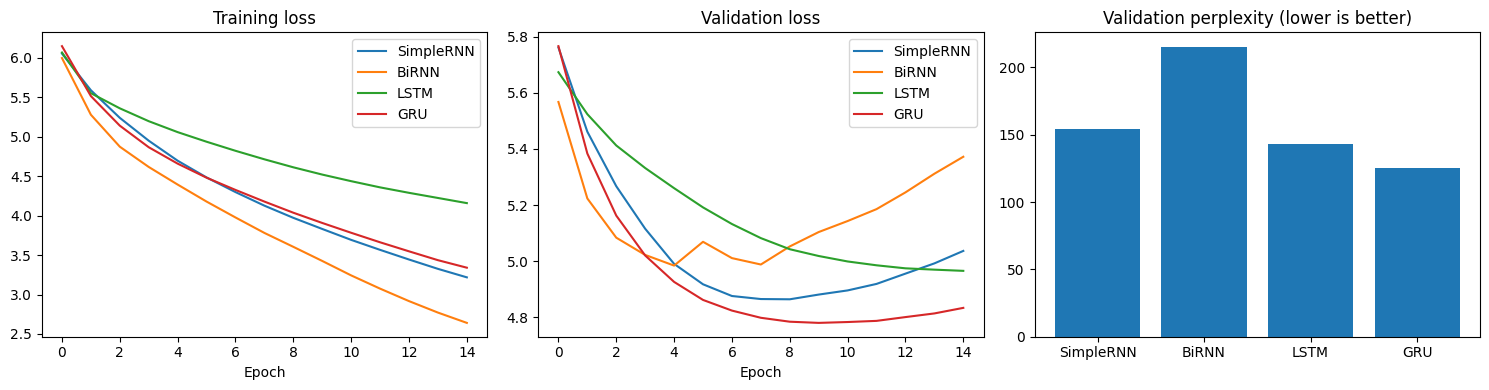

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for k in kinds:
    ax[0].plot(hist[k]["loss"], label=k)
    ax[1].plot(hist[k]["val_loss"], label=k)
ax[0].set_title("Training loss"); ax[1].set_title("Validation loss")
for a in ax[:2]: a.set_xlabel("Epoch"); a.legend()
ax[2].bar(res["Model"], res["Perplexity"]); ax[2].set_title("Validation perplexity (lower is better)")
plt.tight_layout(); plt.savefig("comparison.png", dpi=150); plt.show()

## 6. Text generation with temperature

In [7]:
def sample(probs, t):
    p = np.asarray(probs, dtype="float64"); p[0] = 0; p[1] = 0      # never sample pad/<unk>
    p = np.log(p + 1e-9) / t
    p = np.exp(p - p.max()); p /= p.sum()
    return np.random.choice(len(p), p=p)

def generate(model, seed, n=50, t=1.0):
    cur = tok.texts_to_sequences([seed.lower()])[0][-SEQ:]
    out = []
    for _ in range(n):
        p = model(np.array([cur]), training=False).numpy()[0]
        w = sample(p, t); out.append(w); cur = cur[1:] + [w]
    return [inv[i] for i in out]

def metrics(ws):
    tri = list(zip(ws, ws[1:], ws[2:])); bi = list(zip(ws, ws[1:]))
    return {"distinct1": len(set(ws)) / len(ws), "distinct2": len(set(bi)) / len(bi),
            "repeat_trigram": 1 - len(set(tri)) / len(tri)}

seeds = ["alice was beginning to get very tired of sitting by",
         "the queen turned crimson with fury and glared at her",
         "i do not think said the cat and it grinned"]
temps = [0.5, 1.0, 1.5]
log, mrows = [], []
for k in kinds:
    for t in temps:
        ms = []
        for sd in seeds:
            np.random.seed(SEED)
            ws = generate(trained[k], sd, 50, t)
            log.append(f"[{k} | T={t}] {sd} >> {' '.join(ws)}\n")
            ms.append(metrics(ws))
        d = pd.DataFrame(ms).mean().to_dict(); d.update({"Model": k, "Temp": t}); mrows.append(d)
open("generated_samples.txt", "w").write("\n".join(log))
tm = pd.DataFrame(mrows)[["Model", "Temp", "distinct1", "distinct2", "repeat_trigram"]].round(3)
tm.to_csv("temperature_metrics.csv", index=False)
print("\n".join(log[:9]))
tm

[SimpleRNN | T=0.5] alice was beginning to get very tired of sitting by >> the directions , which said the queen s head to her daughter speaking , and the gryphon s grinned in reply to say it s angry , and holding , said the king . then she had not remember her head in the distant while she was head noticed the

[SimpleRNN | T=0.5] the queen turned crimson with fury and glared at her >> arm when she walked her , and was going to her daughter wink to this , and she went on . it s the same thing , said the king , and the white rabbit blew silence , and the king was the answer to have to look at the

[SimpleRNN | T=0.5] i do not think said the cat and it grinned >> a branch of the house , and a good deal to state of the house , and the dormouse never appeared , and began out of the wood . you re a little pattering of cards , and alice as she could to see the white rabbit blew writing to

[SimpleRNN | T=1.0] alice was beginning to get very tired of sitting by >> the corners man , and alice

,Model,Temp,distinct1,distinct2,repeat_trigram
0,SimpleRNN,0.5,0.633,0.905,0.028
1,SimpleRNN,1.0,0.813,0.993,0.000
2,SimpleRNN,1.5,0.867,1.000,0.000
3,BiRNN,0.5,0.627,0.878,0.056
4,BiRNN,1.0,0.747,0.973,0.014
5,BiRNN,1.5,0.867,0.993,0.000
6,LSTM,0.5,0.580,0.830,0.062
7,LSTM,1.0,0.800,0.986,0.000
8,LSTM,1.5,0.867,1.000,0.000
9,GRU,0.5,0.587,0.823,0.069


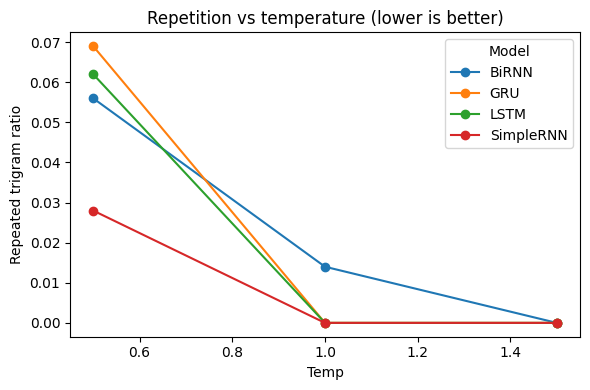

In [8]:
piv = tm.pivot(index="Temp", columns="Model", values="repeat_trigram")
piv.plot(marker="o", figsize=(6, 4), title="Repetition vs temperature (lower is better)")
plt.ylabel("Repeated trigram ratio"); plt.tight_layout(); plt.savefig("temperature_repetition.png", dpi=150); plt.show()

## 7. Analysis
Best model: GRU, with perplexity 125.7 and accuracy 20.6%.
Time: all models trained in 25-33 s. LSTM was slowest, and BiRNN overfit.
T=0.5: coherent but repetitive.
T=1.0: balanced.
T=1.5: diverse but incoherent.
Conclusion: GRU at temperature 0.5-1.0.